# XGBoost - Clumpiness

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

from scipy.stats import pearsonr
from xgboost import XGBRegressor
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# ── Shared repo locations (sf_statistics/src/utils/paths.py) ─────────────────
import sys
from pathlib import Path
_here = Path.cwd().resolve()
REPO_ROOT = next(p for p in [_here, *_here.parents]
                 if (p / 'sf_statistics' / 'src' / 'utils' / 'paths.py').exists())
sys.path.insert(0, str(REPO_ROOT / 'sf_statistics'))
from src.utils.paths import ML_DATA_CSV, ML_IMPORTANCES_DIR

In [2]:
## ── CONFIGURATION ──
# This will be the section I can edit to change the model
# All subsequent cells read from CONFIG

CONFIG = {
    # Target metric: 'G', 'C', 'A', or 'S'
    'target': 'S',

    # Restrict to the full purity/quality-cut sample (in_full_sam == True)?
        # This is the sample all ML analysis should be run on — leave True unless
        # you're deliberately testing on the unfiltered catalogue.
        'require_full_sam': True,

    # Spectral class sample:
    #   'pure_SF'      — pure SF galaxies only  (spectral_class == 0)
    #   'composite_SF' — composite SF only      (spectral_class == 1)
    #   'both'         — all SF galaxies; spectral_class added as a predictor
    'spectral_sample': 'both',

    # Model A or B
    # False = Model A (primary):     no halo mass, full spectral sample
    # True  = Model B (sensitivity): adds log_MassA_1, restricted to non-null halo mass
    'halo_mass': False,

    # Include closest companion distance as a predictor?
    # True  — includes closest_companion_kpc (continuous, NaN = no pair in catalogue)
    # False — excludes closest_companion_kpc entirely
    'include_companion': False,

    # Include cosmic web distances as predictors?
    # Dfil/Dnode/Dvoid (distance to nearest filament/node/void) are only measured
    # for GAMA field galaxies — every Cluster galaxy is NaN for all three.
    # Enabling any of these therefore restricts the sample to field galaxies only
    # (handled automatically by the dropna in the filtering cell below).
    # Each can be toggled independently — e.g. Dvoid is ~uncorrelated with the
    # other two, so it's worth testing on its own.
    'include_Dfil':  False,
    'include_Dnode': False,
    'include_Dvoid': False,

    # Subgroup: 'all', 'field' (environment=0), or 'cluster' (environment=1)
    'subgroup': 'all',

    # Seeing cut: None for no cut, or a float e.g. 0.1
    'seeing_cut': None,

    # ── Hyperparameters (XGBoost) ────────────────────────────────────────────
    'n_estimators':          2000,   # upper cap; early stopping halts before this
    'learning_rate':         0.03,
    'max_depth':              6,
    'reg_lambda':              3.0,   # L2 regularization (XGBoost's analogue to l2_leaf_reg)
    'subsample':               0.8,   # fraction of rows sampled per tree — helps small-dataset overfitting
    'colsample_bytree':        0.8,   # fraction of features sampled per tree
    'early_stopping_rounds': 50,
    'eval_size':               0.15,

    # ── CV and reproducibility ───────────────────────────────────────────────
    'n_folds':     5,
    'random_seed': 42,

    'perm_n_repeats': 10,

    'data_path':  ML_DATA_CSV,
}

# ── Base feature set (always included) ────────────────────────────────────────
BASE_FEATURES = [
    'log_Mstar', 'log_sSFR', '5NN', 'is_satellite', 'is_isolated',
    'is_central', 'is_cluster', 'ellip', 'z', 're', 'delta_ms'
]

# ── Optional features (added based on CONFIG flags) ───────────────────────────
# closest_companion_kpc: included when CONFIG['include_companion'] = True
# log_MassA_1:          included when CONFIG['halo_mass'] = True (Model B)
# Dfil/Dnode/Dvoid:     included when CONFIG['include_Dfil'/'include_Dnode'/'include_Dvoid'] = True
#                       (field-only; forces exclusion of Cluster galaxies)
# spectral_class:       included automatically when CONFIG['spectral_sample'] = 'both'

FEATURES = BASE_FEATURES.copy()

if CONFIG['include_companion']:
    FEATURES.append('closest_companion_kpc')

if CONFIG['halo_mass']:
    FEATURES.append('log_MassA_1')

if CONFIG['include_Dfil']:
    FEATURES.append('Dfil')

if CONFIG['include_Dnode']:
    FEATURES.append('Dnode')

if CONFIG['include_Dvoid']:
    FEATURES.append('Dvoid')

# spectral_class is added later (after filtering) if spectral_sample == 'both'
# because it is constant (and therefore useless) when filtering to a single class

# ── Run label (used in output filenames and plot titles) ──────────────────────
model_variant = 'B' if CONFIG['halo_mass'] else 'A'
RUN_LABEL = f"Model{model_variant}_{CONFIG['target']}_{CONFIG['spectral_sample']}_{CONFIG['subgroup']}"
if not CONFIG['include_companion']:
    RUN_LABEL += '_nocompanion'
cosmic_web_flags = [name for name, flag in
                     [('Dfil', CONFIG['include_Dfil']),
                      ('Dnode', CONFIG['include_Dnode']),
                      ('Dvoid', CONFIG['include_Dvoid'])] if flag]
if cosmic_web_flags:
    RUN_LABEL += '_' + '-'.join(cosmic_web_flags)
if CONFIG['seeing_cut'] is not None:
    RUN_LABEL += f"_seeinglt{CONFIG['seeing_cut']}"

print(f"Run label        : {RUN_LABEL}")
print(f"Spectral sample  : {CONFIG['spectral_sample']}")
print(f"Target           : {CONFIG['target']}")
print(f"Halo mass (B)    : {CONFIG['halo_mass']}")
print(f"Companion dist   : {CONFIG['include_companion']}")
print(f"Cosmic web       : Dfil={CONFIG['include_Dfil']}, Dnode={CONFIG['include_Dnode']}, Dvoid={CONFIG['include_Dvoid']}"
      + (" (restricts sample to GAMA field galaxies)" if cosmic_web_flags else ""))
print(f"Subgroup         : {CONFIG['subgroup']}")
print(f"Seeing cut       : {CONFIG['seeing_cut']}")
print(f"Base features ({len(BASE_FEATURES)}): {BASE_FEATURES}")

Run label        : ModelA_S_both_all_nocompanion
Spectral sample  : both
Target           : S
Halo mass (B)    : False
Companion dist   : False
Cosmic web       : Dfil=False, Dnode=False, Dvoid=False
Subgroup         : all
Seeing cut       : None
Base features (11): ['log_Mstar', 'log_sSFR', '5NN', 'is_satellite', 'is_isolated', 'is_central', 'is_cluster', 'ellip', 'z', 're', 'delta_ms']


## Load Data & Applying Filters

In [3]:
df_raw = pd.read_csv(CONFIG['data_path'])
target = CONFIG['target']

df = df_raw.copy()

# Keep only galaxies with a valid target measurement (drop NaN, +/-inf, and
# the -999 missing-data sentinel that appears in this catalogue)
valid_target = np.isfinite(df[target]) & (df[target] != -999)
df = df[valid_target]

# Restrict to the full purity/quality-cut sample
if CONFIG['require_full_sam']:
    df = df[df['in_full_sam'] == True]

# Spectral class filter
if CONFIG['spectral_sample'] == 'pure_SF':
    df = df[df['spectral_class'] == 'pure_SF']
elif CONFIG['spectral_sample'] == 'composite_SF':
    df = df[df['spectral_class'] == 'composite_SF']
# 'both' keeps everything; spectral_class is added as a feature below

# Optional subgroup filter
if CONFIG['subgroup'] == 'field':
    df = df[df['environment'] == 'GAMA']
elif CONFIG['subgroup'] == 'cluster':
    df = df[df['environment'] == 'Cluster']

# Optional seeing cut
if CONFIG['seeing_cut'] is not None:
    df = df[df['seeing'] <= CONFIG['seeing_cut']]

# Model B — restrict to galaxies with halo mass
if CONFIG['halo_mass']:
    df = df.dropna(subset=['log_MassA_1'])

# Add spectral_class as a feature only when both classes are present
feature_cols = FEATURES.copy()
if CONFIG['spectral_sample'] == 'both':
    feature_cols.append('spectral_class')

df = df.dropna(subset=feature_cols)
print(f"N galaxies after filtering: {len(df)}")
df.head()

N galaxies after filtering: 704


,CATID,C,G,A,S,spectral_class,environment,re,re_kpc,n_res,...,5NN_err,in_full_sam,delta_ms,Dfil,Dnode,Dvoid,is_satellite,is_central,is_isolated,is_cluster
2,7206,0.050523,0.319035,0.262159,0.175119,composite_SF,GAMA,3.33,5.852094,2.221746,...,0.0143,True,0.511836,0.847793,5.237409,11.880854,False,True,False,False
10,8319,-0.012790,NaN,0.253771,0.977369,pure_SF,GAMA,11.72,1.542886,4.256585,...,0.1714,True,-0.604389,NaN,NaN,NaN,False,False,True,False
11,8353,0.040326,0.382265,0.629758,0.214762,pure_SF,GAMA,5.37,2.332199,1.989649,...,0.0261,True,0.312850,1.395220,2.242314,8.374062,False,False,True,False
19,8570,-0.071971,0.317977,0.280710,0.406769,pure_SF,GAMA,4.80,2.169676,2.852864,...,0.5597,True,-0.498352,NaN,NaN,NaN,False,True,False,False
20,8703,0.022114,0.399060,0.149497,0.306544,composite_SF,GAMA,8.39,3.752812,3.352634,...,0.1362,True,0.109155,1.343619,1.862234,6.000984,False,True,False,False


In [4]:
# Add RANDOM baseline feature (drawn fresh every run — never saved to CSV)
# Any feature with importance <= RANDOM is non-informative
rng = np.random.default_rng(CONFIG['random_seed'])
df['RANDOM'] = rng.uniform(0, 1, len(df))
FEATURES.append('RANDOM')

In [5]:
df

,CATID,C,G,A,S,spectral_class,environment,re,re_kpc,n_res,...,in_full_sam,delta_ms,Dfil,Dnode,Dvoid,is_satellite,is_central,is_isolated,is_cluster,RANDOM
2,7206,0.050523,0.319035,0.262159,0.175119,composite_SF,GAMA,3.33,5.852094,2.221746,...,True,0.511836,0.847793,5.237409,11.880854,False,True,False,False,0.773956
10,8319,-0.012790,NaN,0.253771,0.977369,pure_SF,GAMA,11.72,1.542886,4.256585,...,True,-0.604389,NaN,NaN,NaN,False,False,True,False,0.438878
11,8353,0.040326,0.382265,0.629758,0.214762,pure_SF,GAMA,5.37,2.332199,1.989649,...,True,0.312850,1.395220,2.242314,8.374062,False,False,True,False,0.858598
19,8570,-0.071971,0.317977,0.280710,0.406769,pure_SF,GAMA,4.80,2.169676,2.852864,...,True,-0.498352,NaN,NaN,NaN,False,True,False,False,0.697368
20,8703,0.022114,0.399060,0.149497,0.306544,composite_SF,GAMA,8.39,3.752812,3.352634,...,True,0.109155,1.343619,1.862234,6.000984,False,True,False,False,0.094177
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2469,9016800065,-0.103140,0.505760,0.144198,0.127332,composite_SF,Cluster,3.11,3.010246,1.462560,...,True,-0.295411,NaN,NaN,NaN,False,False,False,True,0.299383
2473,9016800074,-0.346120,0.697836,0.156563,0.271170,composite_SF,Cluster,4.79,4.308533,2.252624,...,True,-0.321439,NaN,NaN,NaN,False,False,False,True,0.241372
2480,9016800093,0.029210,0.240138,0.348957,0.287012,composite_SF,Cluster,7.15,6.348893,3.374540,...,True,-0.031702,NaN,NaN,NaN,False,False,False,True,0.322492
2482,9016800095,-0.238280,0.603134,0.219906,0.224573,pure_SF,Cluster,4.61,4.158615,2.352938,...,True,0.201943,NaN,NaN,NaN,False,False,False,True,0.155442


In [6]:
# Build X and y
X = df[FEATURES].values
y = df[target].values
feature_names = FEATURES
stratify_labels = df['environment'].values

print(f"Final sample     : {len(y):,} galaxies")
print(f"Features ({len(feature_names):>2})    : {feature_names}")
print(f"Target range, {target}: {y.min():.4f}  to  {y.max():.4f}  (mean={y.mean():.4f})")

Final sample     : 704 galaxies
Features (12)    : ['log_Mstar', 'log_sSFR', '5NN', 'is_satellite', 'is_isolated', 'is_central', 'is_cluster', 'ellip', 'z', 're', 'delta_ms', 'RANDOM']
Target range, S: 0.0883  to  0.9846  (mean=0.3527)


Exploring the Dataset

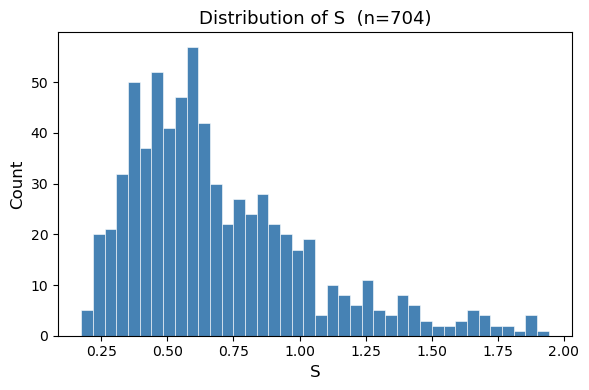

In [7]:
# Target distribution
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(y, bins=40, color='steelblue', edgecolor='white', linewidth=0.4)
ax.set_xlabel(target, fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title(f'Distribution of {target}  (n={len(y):,})', fontsize=13)
plt.tight_layout()
plt.show()

/var/folders/c_/tzlzsfx57gxd_3zb7_32pscw0000gn/T/ipykernel_25868/638986611.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in corr_df.select_dtypes(include='object').columns:


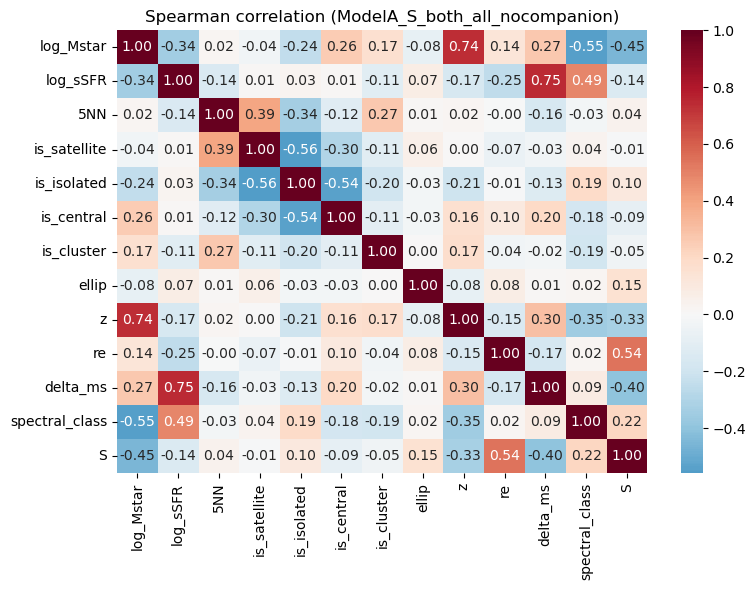

In [8]:
# Spearman correlation matrix
# (categorical string columns are code-mapped here just for the correlation
# computation; AutoGluon itself consumes them as native categoricals below)
corr_df = df[feature_cols + [target]].copy()
for col in corr_df.select_dtypes(include='object').columns:
    corr_df[col] = corr_df[col].astype('category').cat.codes

corr = corr_df.corr(method='spearman')
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title(f'Spearman correlation ({RUN_LABEL})')
plt.tight_layout()
plt.show()

5-Fold Stratified Cross Validation Loop

In [7]:
# ── Initialise storage ───────────────────────────────────────────────────────
fold_r2, fold_rmse, fold_mae = [], [], []
fold_best_iter = []
gain_importances  = []
perm_importances = []
oof_true = np.zeros(len(y))
oof_pred = np.zeros(len(y))

# ── Cross Validation splitter (stratified on environment) ────────────────────
skf = StratifiedKFold(
    n_splits=CONFIG['n_folds'],
    shuffle=True,
    random_state=CONFIG['random_seed'],
)

def build_xgboost(seed_offset=0):
    return XGBRegressor(
        n_estimators         = CONFIG['n_estimators'],
        learning_rate        = CONFIG['learning_rate'],
        max_depth            = CONFIG['max_depth'],
        reg_lambda           = CONFIG['reg_lambda'],
        subsample             = CONFIG['subsample'],
        colsample_bytree      = CONFIG['colsample_bytree'],
        early_stopping_rounds = CONFIG['early_stopping_rounds'],
        eval_metric           = 'rmse',
        random_state          = CONFIG['random_seed'] + seed_offset,
        n_jobs                = -1,
        importance_type       = 'gain',   # see importance note below — avoids relying on the ambiguous default
    )

# ── Main CV loop (identical structure to CatBoost — same inner/outer split) ──
for fold_idx, (train_idx, test_idx) in enumerate(skf.split(X, stratify_labels)):

    X_train_full, X_test = X[train_idx], X[test_idx]
    y_train_full, y_test = y[train_idx], y[test_idx]
    strat_train_full = stratify_labels[train_idx]

    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full,
        test_size=CONFIG['eval_size'],
        random_state=CONFIG['random_seed'] + fold_idx,
        stratify=strat_train_full,
    )

    xgb_model = build_xgboost(seed_offset=fold_idx)
    xgb_model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False,
    )
    y_pred = xgb_model.predict(X_test)

    oof_true[test_idx] = y_test
    oof_pred[test_idx] = y_pred

    r2   = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae  = mean_absolute_error(y_test, y_pred)
    best_iter = xgb_model.best_iteration

    fold_r2.append(r2); fold_rmse.append(rmse); fold_mae.append(mae)
    fold_best_iter.append(best_iter)

    gain_importances.append(xgb_model.feature_importances_)

    perm_result = permutation_importance(
        xgb_model, X_test, y_test,
        n_repeats=CONFIG['perm_n_repeats'],
        random_state=CONFIG['random_seed'] + fold_idx,
        n_jobs=-1, scoring='r2',
    )
    perm_importances.append(perm_result.importances_mean)

    print(f"{fold_idx+1:>5}  {len(y_train):>8,}  {len(y_val):>6,}  {len(y_test):>7,}  {r2:>8.4f}  {rmse:>8.4f}  {mae:>8.4f}  {best_iter:>8}")

print("-" * 75)
print(f"{'Mean':>5}  {'':>8}  {'':>6}  {'':>7}  {np.mean(fold_r2):>8.4f}  {np.mean(fold_rmse):>8.4f}  {np.mean(fold_mae):>8.4f}")
print(f"{'Std':>5}  {'':>8}  {'':>6}  {'':>7}  {np.std(fold_r2):>8.4f}  {np.std(fold_rmse):>8.4f}  {np.std(fold_mae):>8.4f}")

    1       478      85      141    0.7069    0.1006    0.0745       438
    2       478      85      141    0.5801    0.0834    0.0666       271
    3       478      85      141    0.6385    0.1163    0.0798       321
    4       478      85      141    0.6361    0.1110    0.0782       276
    5       479      85      140    0.6059    0.1134    0.0788       490
---------------------------------------------------------------------------
 Mean                               0.6335    0.1049    0.0756
  Std                               0.0425    0.0120    0.0048


Performance Summary and Predicted vs Actual Plot

=== Performance Summary  --  ModelA_S_both_all_nocompanion ===
Metric   Mean    Std    Min    Max
    R2 0.6335 0.0425 0.5801 0.7069
  RMSE 0.1049 0.0120 0.0834 0.1163
   MAE 0.0756 0.0048 0.0666 0.0798


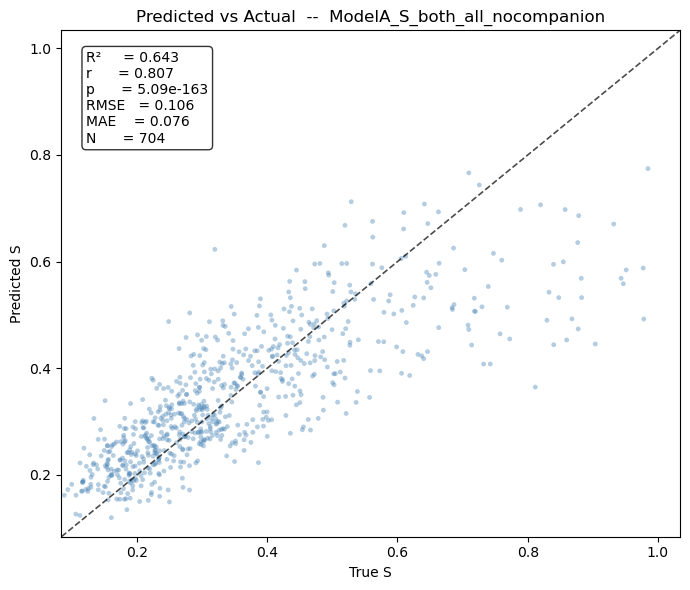

In [8]:
# Performance summary table
perf_df = pd.DataFrame({
    'Metric': ['R2', 'RMSE', 'MAE'],
    'Mean':   [np.mean(fold_r2),   np.mean(fold_rmse),   np.mean(fold_mae)],
    'Std':    [np.std(fold_r2),    np.std(fold_rmse),    np.std(fold_mae)],
    'Min':    [np.min(fold_r2),    np.min(fold_rmse),    np.min(fold_mae)],
    'Max':    [np.max(fold_r2),    np.max(fold_rmse),    np.max(fold_mae)],
})
print(f"=== Performance Summary  --  {RUN_LABEL} ===")
print(perf_df.to_string(index=False, float_format='{:.4f}'.format))
# perf_df.to_csv(os.path.join(CONFIG['output_dir'], f'{RUN_LABEL}_performance.csv'), index=False)

# Predicted vs Actual scatter (out-of-fold — full sample, no leakage)
overall_r2   = r2_score(oof_true, oof_pred)
overall_rmse = np.sqrt(mean_squared_error(oof_true, oof_pred))
overall_mae  = mean_absolute_error(oof_true, oof_pred)

r_pearson, p_pearson = pearsonr(oof_true, oof_pred)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(oof_true, oof_pred, s=12, alpha=0.4, color='steelblue',
           edgecolors='none', rasterized=True)
lims = [min(oof_true.min(), oof_pred.min()) * 0.95,
        max(oof_true.max(), oof_pred.max()) * 1.05]
ax.plot(lims, lims, 'k--', linewidth=1.2, alpha=0.7)
ax.set_xlim(lims); ax.set_ylim(lims)
textstr = (f'R²     = {overall_r2:.3f}\n'
           f'r      = {r_pearson:.3f}\n'
           f'p      = {p_pearson:.2e}\n'
           f'RMSE   = {overall_rmse:.3f}\n'
           f'MAE    = {overall_mae:.3f}\n'
           f'N      = {len(oof_true):,}')
ax.text(0.04, 0.96, textstr, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.set_xlabel(f'True {target}'); ax.set_ylabel(f'Predicted {target}')
ax.set_title(f'Predicted vs Actual  --  {RUN_LABEL}')
plt.tight_layout()
plt.show()

In [9]:
# Save performance summary for the thesis figure (importances/ folder)
IMPORTANCES_DIR = ML_IMPORTANCES_DIR
os.makedirs(IMPORTANCES_DIR, exist_ok=True)
perf_out_path = os.path.join(IMPORTANCES_DIR, f'XGBoost_{target}_performance.csv')
perf_df.to_csv(perf_out_path, index=False)
print(f"Saved {perf_out_path}")

Saved /Users/sophiesinclair/Desktop/sami copy/outputs/ch4/importances/XGBoost_S_performance.csv


Feature Importance: Permutation (Primary) and MDI (Secondary)

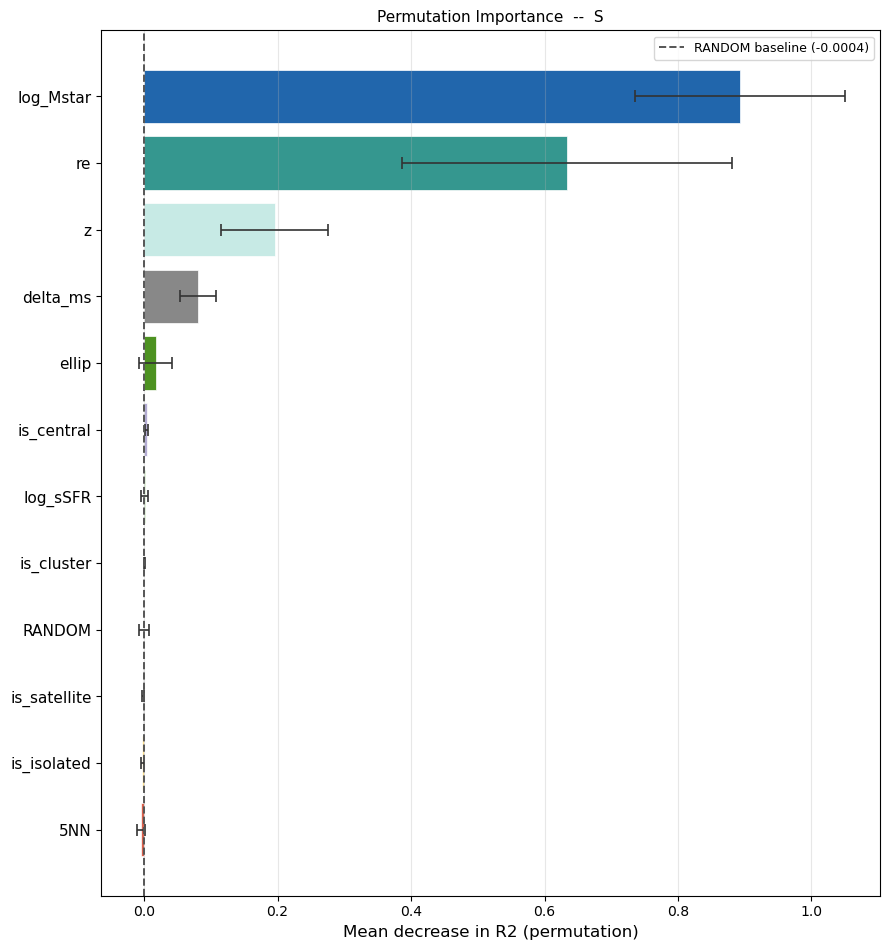

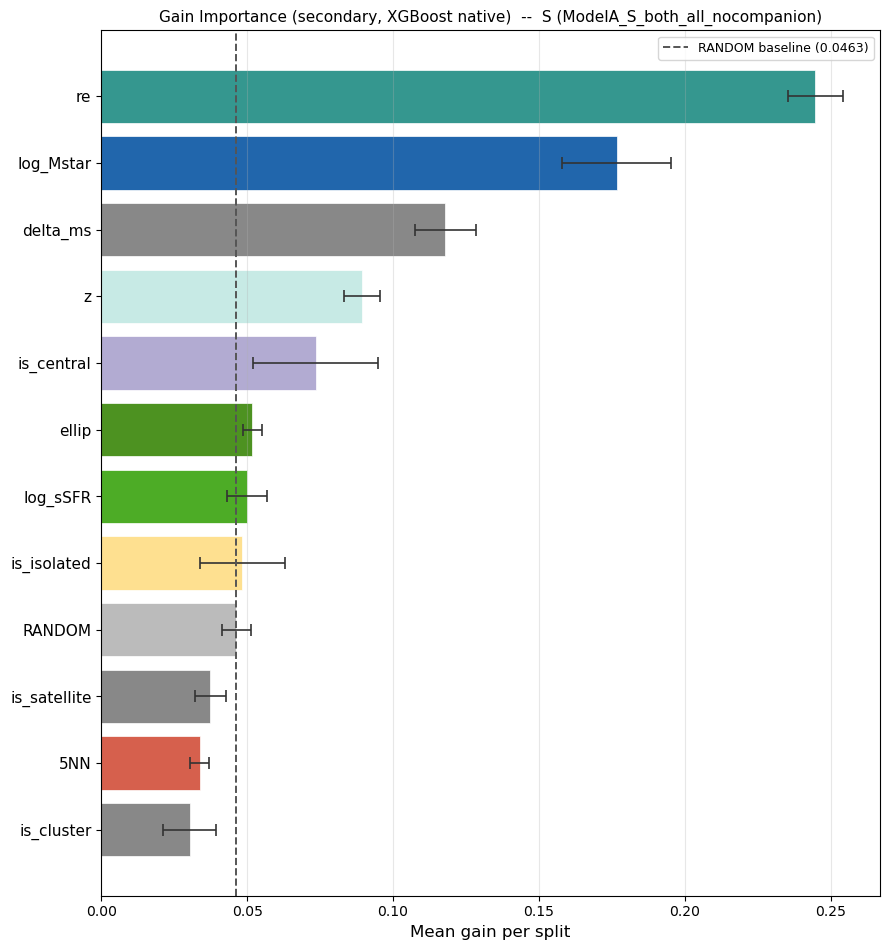

In [10]:
# Aggregate importances across folds
gain_array  = np.array(gain_importances)   # from Cell 11 — CatBoost's PredictionValuesChange, computed per fold
perm_array = np.array(perm_importances)

perm_df = pd.DataFrame({
    'Feature': feature_names, 'Perm_Mean': perm_array.mean(axis=0),
    'Perm_Std': perm_array.std(axis=0),
}).sort_values('Perm_Mean', ascending=False).reset_index(drop=True)

gain_df = pd.DataFrame({
    'Feature': feature_names, 'Gain_Mean': gain_array.mean(axis=0),
    'Gain_Std': gain_array.std(axis=0),
}).sort_values('Gain_Mean', ascending=False).reset_index(drop=True)

random_perm = perm_df.loc[perm_df['Feature'] == 'RANDOM', 'Perm_Mean'].values[0]
random_gain  = gain_df.loc[gain_df['Feature']  == 'RANDOM', 'Gain_Mean'].values[0]

# Feature colour map — add new features, keep existing colours consistent
FEATURE_COLOURS = {
    'log_Mstar':              '#2166AC',  # dark blue   -- stellar mass
    'log_sSFR':               '#4DAC26',  # green       -- SF activity
    '5NN':                    '#D6604D',  # red         -- local density
    'environment':            '#F4A582',  # light red   -- broad environment
    'is_isolated':            '#FEE090',  # yellow      -- isolation
    'closest_companion_kpc':  '#92C5DE',  # light blue  -- interaction distance
    'log_MassA_1':            '#762A83',  # purple      -- halo mass (Model B)
    'is_central':              '#B2ABD2',  # lavender    -- central/satellite
    'ellip':                  '#4D9221',  # dark green  -- structural
    'z':                      '#C7EAE5',  # pale teal   -- redshift
    're':                     '#35978F',  # teal        -- galaxy size
    'spectral_class':         '#E08214',  # orange      -- SF class (both only)
    'Dfil':                   '#A6761D',  # brown/gold  -- distance to filament
    'Dnode':                  '#E7298A',  # magenta     -- distance to node
    'Dvoid':                  '#666666',  # dark grey   -- distance to void
    'RANDOM':                 '#BBBBBB',  # grey        -- noise baseline
}

def importance_bar_chart(df_imp, mean_col, std_col, random_val, title, xlabel, filename):
    n = len(df_imp)
    fig, ax = plt.subplots(figsize=(9, 0.65 * n + 1.8))
    features = df_imp['Feature'].tolist()
    means, stds = df_imp[mean_col].values, df_imp[std_col].values
    colours = [FEATURE_COLOURS.get(f, '#888888') for f in features]
    y_pos = np.arange(n)[::-1]
    ax.barh(y_pos, means, xerr=stds, capsize=4, color=colours,
            edgecolor='white', linewidth=0.5,
            error_kw={'elinewidth': 1.2, 'ecolor': '#333333', 'capthick': 1.2})
    ax.axvline(random_val, color='#555555', linestyle='--', linewidth=1.4,
               label=f'RANDOM baseline ({random_val:.4f})')
    ax.set_yticks(y_pos); ax.set_yticklabels(features, fontsize=11)
    ax.set_xlabel(xlabel, fontsize=12); ax.set_title(title, fontsize=11)
    ax.legend(fontsize=9); ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

importance_bar_chart(perm_df, 'Perm_Mean', 'Perm_Std', random_perm,
    title=f'Permutation Importance  --  {target}',
    xlabel='Mean decrease in R2 (permutation)',
    filename=f'{RUN_LABEL}_perm_importance.png')

importance_bar_chart(gain_df, 'Gain_Mean', 'Gain_Std', random_gain,
    title=f'Gain Importance (secondary, XGBoost native)  --  {target} ({RUN_LABEL})',
    xlabel='Mean gain per split',
    filename=f'{RUN_LABEL}_gain_importance.png')

In [11]:
# Save importance numbers for the thesis figure (importances/ folder)
IMPORTANCES_DIR = ML_IMPORTANCES_DIR
os.makedirs(IMPORTANCES_DIR, exist_ok=True)
importance_out = perm_df.merge(gain_df, on='Feature')
imp_out_path = os.path.join(IMPORTANCES_DIR, f'XGBoost_{target}.csv')
importance_out.to_csv(imp_out_path, index=False)
print(f"Saved {imp_out_path}")

Saved /Users/sophiesinclair/Desktop/sami copy/outputs/ch4/importances/XGBoost_S.csv


## Feature Relationship Explorer

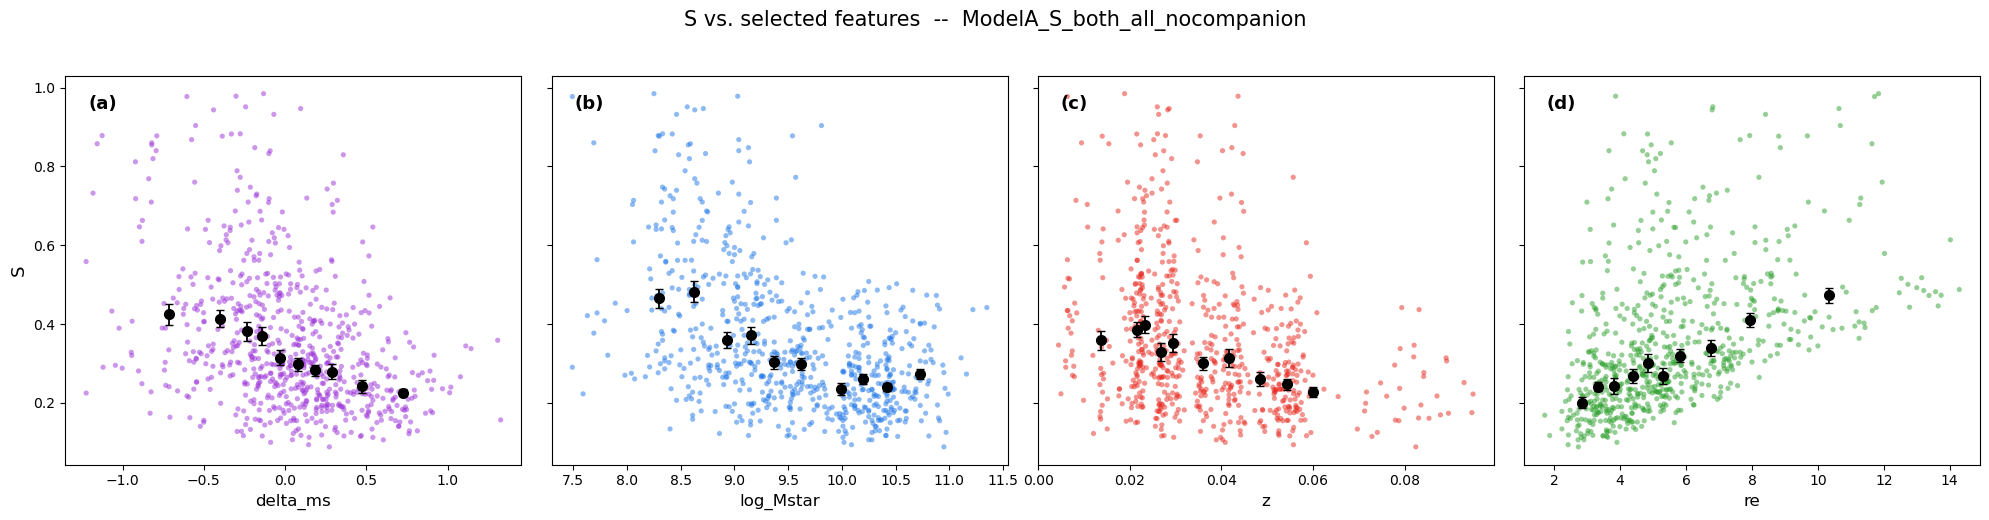

In [12]:
FEATURES_TO_PLOT = ['delta_ms', 'log_Mstar', 'z', 're']  

N_BINS = 10
PANEL_COLOURS = ['#9B30D9', '#1F77E8', '#E8291F', '#2CA02C']  
PANEL_LETTERS = ['(a)', '(b)', '(c)', '(d)']

assert len(FEATURES_TO_PLOT) == 4, "Pick exactly 4 features for the 1x4 row"
for f in FEATURES_TO_PLOT:
    assert f in df.columns, f"'{f}' not found in df — check spelling against FEATURES"

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

for i, (ax, feat) in enumerate(zip(axes, FEATURES_TO_PLOT)):
    colour = PANEL_COLOURS[i]
    is_binary = df[feat].nunique() <= 2
    n_points = df[[feat, target]].dropna().shape[0]

    if is_binary:
        sns.boxplot(
            data=df, x=feat, y=target, ax=ax,
            color=colour, width=0.5, fliersize=2,
            boxprops=dict(alpha=0.75), medianprops=dict(color='black', linewidth=1.5),
        )

    else:
        x = df[feat].values
        y = df[target].values

        ax.scatter(x, y, s=14, alpha=0.5, color=colour, edgecolors='none', rasterized=True)

        # Binned medians (black points, error bars only — no connecting line)
        bin_edges = np.nanquantile(x, np.linspace(0, 1, N_BINS + 1))
        bin_edges = np.unique(bin_edges)
        bin_idx = np.digitize(x, bin_edges[1:-1])

        bin_x, bin_y, bin_yerr = [], [], []
        for b in range(len(bin_edges) - 1):
            mask = bin_idx == b
            if mask.sum() < 3:
                continue
            bin_x.append(np.median(x[mask]))
            bin_y.append(np.median(y[mask]))
            bin_yerr.append(np.std(y[mask]) / np.sqrt(mask.sum()))

        ax.errorbar(bin_x, bin_y, yerr=bin_yerr, fmt='o', color='black',
                     markerfacecolor='black', markersize=7, linewidth=1.3,
                     capsize=3, zorder=5)


    # Panel letter, top-left
    ax.text(0.05, 0.95, PANEL_LETTERS[i], transform=ax.transAxes,
            fontsize=13, fontweight='bold', va='top', ha='left')

    ax.set_xlabel(feat, fontsize=12)
    if i == 0:
        ax.set_ylabel(target, fontsize=13)

fig.suptitle(f'{target} vs. selected features  --  {RUN_LABEL}', fontsize=15, y=1.03)
plt.tight_layout()
plt.show()

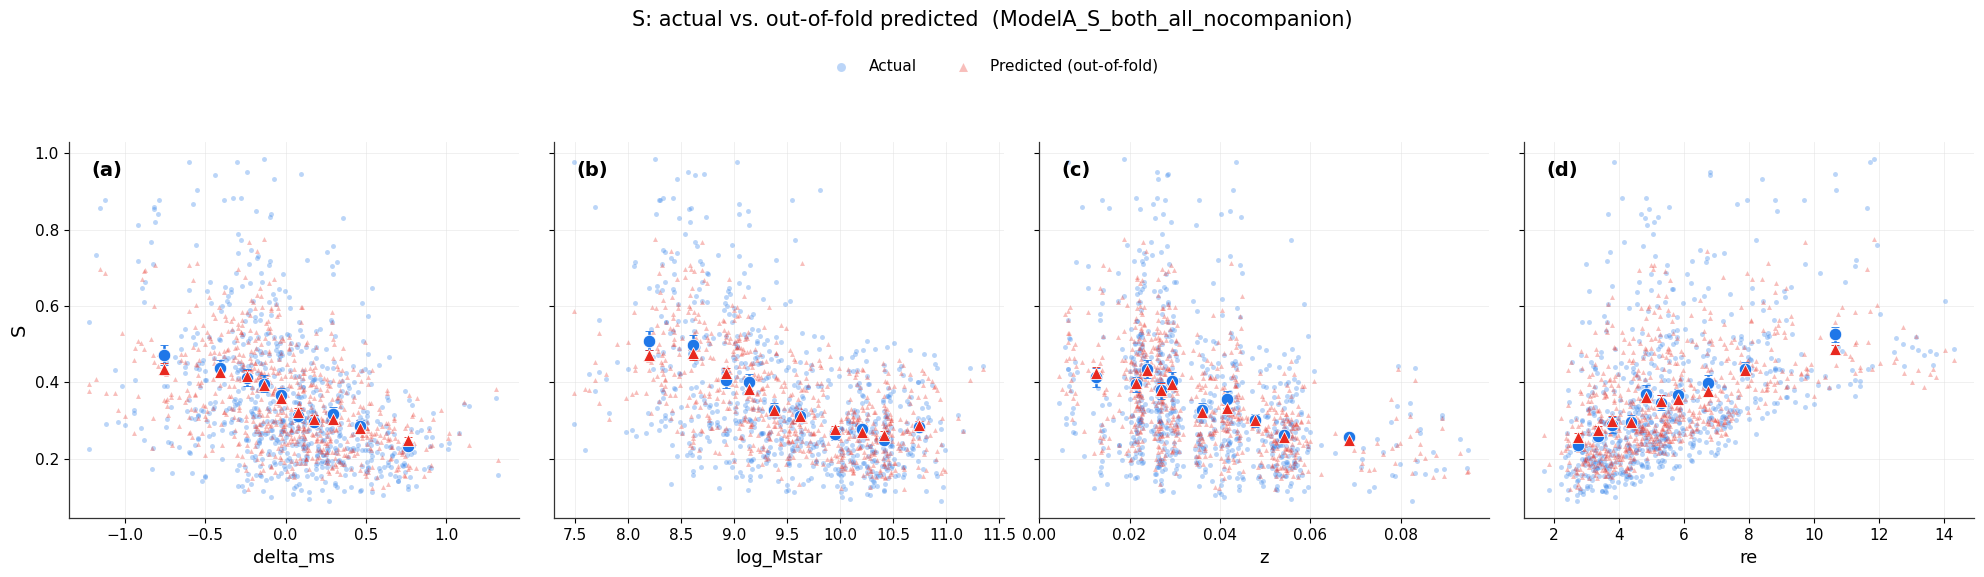

In [13]:
## ── Actual vs. Predicted vs. Feature (out-of-fold, full 5-fold CV) — thesis-ready ──

FEATURES_TO_PLOT = ['delta_ms', 'log_Mstar', 'z', 're']
PANEL_LETTERS = ['(a)', '(b)', '(c)', '(d)']
N_BINS = 10

# Colourblind-safe, higher-contrast pair (Okabe–Ito)
CATEGORY_COLOURS = {
    'Actual':    '#1F77E8',  # deep blue
    'Predicted': '#E8291F',  # vermillion
}

assert len(FEATURES_TO_PLOT) == 4, "Pick exactly 4 features for the 1x4 row"
for f in FEATURES_TO_PLOT:
    assert f in df.columns, f"'{f}' not found in df — check spelling against FEATURES"

def binned_trend(x, y, n_bins=N_BINS):
    """Same binning approach as the Feature Relationship Explorer cell."""
    bin_edges = np.nanquantile(x, np.linspace(0, 1, n_bins + 1))
    bin_edges = np.unique(bin_edges)
    bin_idx = np.digitize(x, bin_edges[1:-1])
    bx, by, byerr = [], [], []
    for b in range(len(bin_edges) - 1):
        mask = bin_idx == b
        if mask.sum() < 3:
            continue
        bx.append(np.mean(x[mask]))
        by.append(np.mean(y[mask]))
        byerr.append(np.std(y[mask]) / np.sqrt(mask.sum()))
    return np.array(bx), np.array(by), np.array(byerr)

with plt.rc_context({
    'font.size': 12,
    'axes.labelsize': 13,
    'axes.titlesize': 13,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#333333',
    'axes.linewidth': 0.9,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'grid.color': '#dddddd',
    'grid.linewidth': 0.6,
}):
    fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

    for i, (ax, feat) in enumerate(zip(axes, FEATURES_TO_PLOT)):
        x = df[feat].values

        # Scatter — small, low alpha, thin white edge to keep it crisp rather than muddy
        ax.scatter(x, oof_true, s=13, alpha=0.30, color=CATEGORY_COLOURS['Actual'],
                   edgecolors='white', linewidths=0.15, label='Actual', rasterized=True, zorder=2)
        ax.scatter(x, oof_pred, s=13, alpha=0.30, marker='^', color=CATEGORY_COLOURS['Predicted'],
                   edgecolors='white', linewidths=0.15, label='Predicted (out-of-fold)',
                   rasterized=True, zorder=2)

        # Binned trend lines — this is what actually sells the story
        bx, by_true, byerr_true = binned_trend(x, oof_true)
        bx, by_pred, byerr_pred = binned_trend(x, oof_pred)
        ax.errorbar(bx, by_true, yerr=byerr_true, fmt='o', color=CATEGORY_COLOURS['Actual'],
                    markersize=9, linewidth=1.8, capsize=3, zorder=4,
                    markeredgecolor='white', markeredgewidth=0.6)
        ax.errorbar(bx, by_pred, yerr=byerr_pred, fmt='^', color=CATEGORY_COLOURS['Predicted'],
                    markersize=9, linewidth=1.8, capsize=3, zorder=4,
                    markeredgecolor='white', markeredgewidth=0.6)

        ax.text(0.05, 0.95, PANEL_LETTERS[i], transform=ax.transAxes,
                fontsize=14, fontweight='bold', va='top', ha='left')
        ax.set_xlabel(feat, fontsize=13)
        if i == 0:
            ax.set_ylabel(target, fontsize=14)
        ax.grid(alpha=0.5, zorder=0)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles[:2], labels[:2], loc='upper center', bbox_to_anchor=(0.5, 1.08),
               ncol=2, fontsize=11, frameon=False, markerscale=1.8)
    fig.suptitle(f'{target}: actual vs. out-of-fold predicted  ({RUN_LABEL})',
                 fontsize=15, y=1.15)
    plt.tight_layout()
    plt.show()